# Forecasting staple prices: SARIMA vs seasonal-naive (#21)

**Business question 5:** where are staple prices likely heading next year?

This notebook adds a second model to the seasonal-naive baseline (#20) and checks it with time-based validation. It covers the 8 agreed staples for Canada and the 10 provinces, 87 series in all.

- **Model:** SARIMA on log(price). For each series and training window, a small grid of orders is fitted and the one with the lowest AIC is kept.
- **Baseline:** seasonal naive, where the forecast is the price in the same month last year.
- **Validation:** rolling origin. Three folds, each trained only on data before a 12-month test year.

The model code lives in `models/sarima/sarima.py`, and this notebook reads its outputs. Set `RERUN = True` to refit everything, which takes about 5 minutes.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "models" / "sarima"))
import sarima

RERUN = False  # True refits every model (about 5 minutes)

OUT = ROOT / "models" / "sarima"
if RERUN or not (OUT / "sarima_metrics.csv").exists():
    sarima.run(verbose=False)

backtest = pd.read_csv(OUT / "sarima_backtest.csv", parse_dates=["date"])
metrics = pd.read_csv(OUT / "sarima_metrics.csv")
future = pd.read_csv(OUT / "sarima_forecasts.csv", parse_dates=["date"])
prices = sarima.load_prices()
print(f"{metrics[['province_code', 'product']].drop_duplicates().shape[0]} series, "
      f"{metrics['fold'].nunique()} folds")

Read 10,265 staple prices from data/raw/18100245_prices.csv
87 series, 3 folds


## Validation design

Each fold trains on every month up to its cut-off, then forecasts the next 12 months without seeing them. The orders are chosen again for every fold, so the test year never influences which model is picked.

| Fold | Trained up to | Test year |
|---|---|---|
| 1 | Sep 2023 | Oct 2023 to Sep 2024 |
| 2 | Sep 2024 | Oct 2024 to Sep 2025 |
| 3 | Sep 2025 | Oct 2025 to Sep 2026 (same holdout as the #20 baseline) |

The folds cover three different price regimes: inflation cooling after the 2022 to 2023 peak, a calmer year, and the latest year.

In [2]:
summary = (metrics.groupby(["fold", "model"])[["mae", "rmse", "mape_pct"]].mean()
           .unstack("model").round(2))
wide = metrics.pivot_table(index=["province_code", "product", "fold"], columns="model", values="rmse")
summary[("sarima wins", "% of series")] = ((wide["sarima"] < wide["seasonal_naive"])
                                           .groupby("fold").mean() * 100).round(0)
summary

mae                  rmse                mape_pct                 \
model sarima seasonal_naive sarima seasonal_naive   sarima seasonal_naive   
fold                                                                        
1       0.46           0.44   0.54           0.51     6.34           5.18   
2       0.36           0.65   0.45           0.74     4.23           6.79   
3       0.39           0.68   0.46           0.77     5.00           6.89   

      sarima wins  
model % of series  
fold               
1            36.0  
2            74.0  
3            75.0

## Canada, fold 3 (the baseline's holdout)

This is the same 12-month holdout used in `models/baseline/README.md`, so the seasonal-naive column should match that table.

In [3]:
ca3 = metrics.query("province_code == 'CA' and fold == 3").pivot_table(
    index="product", columns="model", values=["rmse", "mape_pct"]).round(2)
ca3[("rmse change %", "")] = ((ca3[("rmse", "sarima")] / ca3[("rmse", "seasonal_naive")] - 1) * 100).round(0)
ca3.sort_values(("rmse change %", ""))

mape_pct                  rmse  \
model                                 sarima seasonal_naive sarima   
product                                                              
Ground beef, per kilogram               1.94          12.01   0.38   
Milk, 4 litres                          1.41           3.02   0.11   
Chicken breasts, per kilogram           4.59           6.13   0.75   
Roasted or ground coffee, 340 grams    10.51          15.16   1.25   
White bread, 675 grams                  2.68           3.34   0.10   
Butter, 454 grams                       1.90           1.62   0.13   
Bananas, per kilogram                   6.92           7.81   0.16   
Eggs, 1 dozen                           6.18           1.76   0.31   

                                                   rmse change %  
model                               seasonal_naive                
product                                                           
Ground beef, per kilogram                     1.97         -81.0  
Milk, 4 litres                                0.21         -48.0  
Chicken breasts, per kilogram                 1.11         -32.0  
Roasted or ground coffee, 340 grams           1.71         -27.0  
White bread, 675 grams                        0.13         -23.0  
Butter, 454 grams                             0.15         -13.0  
Bananas, per kilogram                         0.17          -6.0  
Eggs, 1 dozen                                 0.10         210.0

## Error by staple, averaged over all folds and geographies

In [4]:
by_product = metrics.pivot_table(index="product", columns="model", values=["mape_pct", "rmse"]).round(2)
by_product[("sarima wins %", "")] = (wide["sarima"] < wide["seasonal_naive"]).groupby("product").mean().mul(100).round(0)
by_product.sort_values(("sarima wins %", ""), ascending=False)

mape_pct                  rmse  \
model                                 sarima seasonal_naive sarima   
product                                                              
Ground beef, per kilogram               3.82          12.59   0.64   
Milk, 4 litres                          1.46           2.74   0.12   
Chicken breasts, per kilogram           6.88           6.64   1.15   
Roasted or ground coffee, 340 grams     9.01          12.05   0.91   
White bread, 675 grams                  4.63           3.86   0.19   
Bananas, per kilogram                   3.98           3.98   0.09   
Eggs, 1 dozen                           5.53           4.28   0.30   
Butter, 454 grams                       5.89           3.84   0.41   

                                                   sarima wins %  
model                               seasonal_naive                
product                                                           
Ground beef, per kilogram                     1.90         100.0  
Milk, 4 litres                                0.21          87.0  
Chicken breasts, per kilogram                 1.24          70.0  
Roasted or ground coffee, 340 grams           1.22          67.0  
White bread, 675 grams                        0.16          52.0  
Bananas, per kilogram                         0.09          48.0  
Eggs, 1 dozen                                 0.25          45.0  
Butter, 454 grams                             0.29          24.0

## Canada: history, fold 3 backtest and next-12-month forecast

The black line is the actual price. The dashed lines are the fold 3 backtests, and the shaded band is the 80% interval on SARIMA's forecast for the next 12 months.

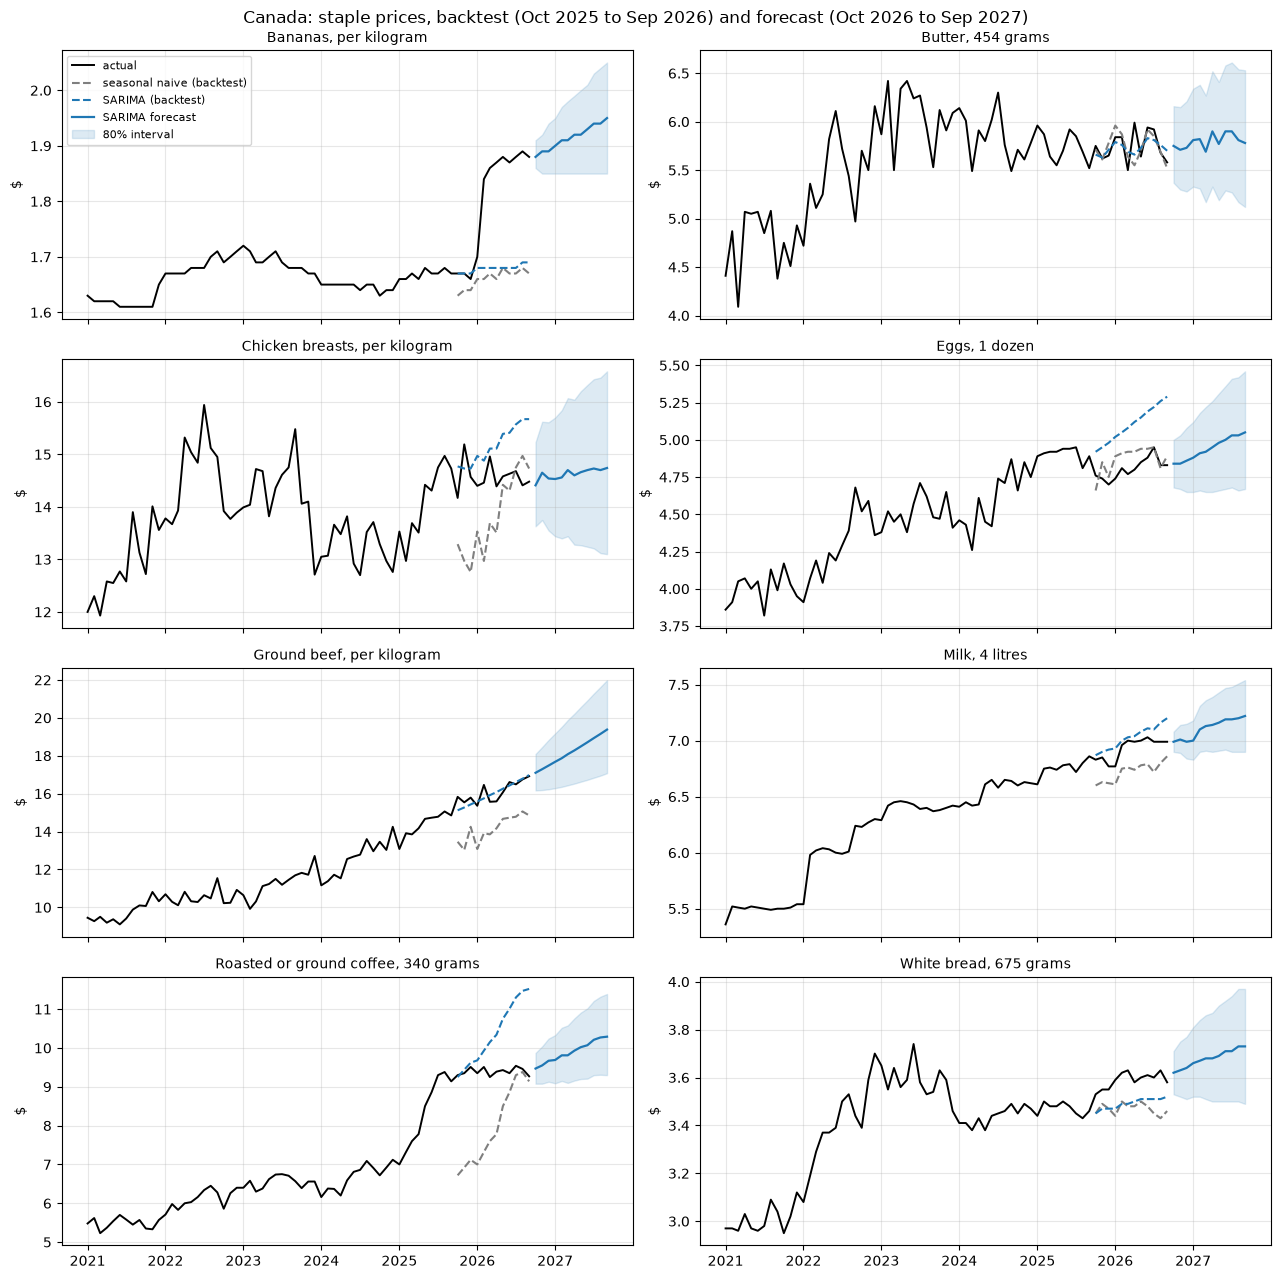

In [5]:
ca_hist = prices.query("province_code == 'CA' and date >= '2021-01-01'")
ca_bt = backtest.query("province_code == 'CA' and fold == 3")
ca_fc = future.query("province_code == 'CA'")

fig, axes = plt.subplots(4, 2, figsize=(13, 13), sharex=True)
for ax, (prod, hist) in zip(axes.flat, ca_hist.groupby("product")):
    bt, fc = ca_bt[ca_bt["product"] == prod], ca_fc[ca_fc["product"] == prod]
    ax.plot(hist["date"], hist["price"], color="black", lw=1.4, label="actual")
    ax.plot(bt["date"], bt["seasonal_naive"], color="tab:gray", ls="--", label="seasonal naive (backtest)")
    ax.plot(bt["date"], bt["sarima"], color="tab:blue", ls="--", label="SARIMA (backtest)")
    ax.plot(fc["date"], fc["forecast"], color="tab:blue", lw=1.6, label="SARIMA forecast")
    ax.fill_between(fc["date"], fc["lower_80"], fc["upper_80"], color="tab:blue", alpha=0.15, label="80% interval")
    ax.set_title(prod, fontsize=10)
    ax.set_ylabel("$")
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8, loc="upper left")
fig.suptitle("Canada: staple prices, backtest (Oct 2025 to Sep 2026) and forecast (Oct 2026 to Sep 2027)")
fig.tight_layout()

## Forecast: Canada, Sep 2027 vs latest price

In [6]:
latest = prices.query("province_code == 'CA'").sort_values("date").groupby("product").last()["price"]
end = ca_fc.sort_values("date").groupby("product").last()
outlook = pd.DataFrame({
    "latest (Sep 2026)": latest,
    "forecast Sep 2027": end["forecast"],
    "80% interval": end["lower_80"].round(2).astype(str) + " to " + end["upper_80"].round(2).astype(str),
})
outlook["change %"] = ((outlook["forecast Sep 2027"] / outlook["latest (Sep 2026)"] - 1) * 100).round(1)
outlook.round(2).sort_values("change %", ascending=False)

,latest (Sep 2026),forecast Sep 2027,80% interval,change %
product,,,,
"Ground beef, per kilogram",16.92,19.38,17.08 to 21.99,14.5
"Roasted or ground coffee, 340 grams",9.27,10.29,9.3 to 11.39,11.0
"Eggs, 1 dozen",4.83,5.05,4.67 to 5.46,4.6
"White bread, 675 grams",3.58,3.73,3.49 to 3.97,4.2
"Bananas, per kilogram",1.88,1.95,1.85 to 2.05,3.7
"Butter, 454 grams",5.58,5.78,5.12 to 6.53,3.6
"Milk, 4 litres",6.99,7.22,6.9 to 7.54,3.3
"Chicken breasts, per kilogram",14.48,14.74,13.1 to 16.58,1.8


## Findings

1. **SARIMA beats the baseline in 2 of the 3 folds.** In folds 2 and 3 it lowers average MAPE from about 6.8% to 4.2% (fold 2) and 5.0% (fold 3), and it has the lower RMSE on about three quarters of the series.
2. **It loses in fold 1 (Oct 2023 to Sep 2024).** That fold was trained up to Sep 2023, just after the 2022 to 2023 inflation spike. The drift term carried that steep rise forward while prices were cooling, so a "same as last year" forecast did better. SARIMA wins on only 36% of series there.
3. **Trending staples gain the most.** Ground beef wins in every fold and geography (100%), milk in 87% and chicken breasts in 70%. For ground beef in Canada, fold 3 MAPE falls from 12.0% to 1.9%.
4. **Volatile or flat staples gain little.** Butter (24%), eggs (45%) and bananas (48%) do as well or better with the seasonal-naive forecast. In Canada, eggs get worse in fold 3 (MAPE from 1.8% to 6.2%).
5. **Both models miss sudden moves.** Bananas jumped about 10% in early 2026, and neither model saw it coming. For coffee, SARIMA beat the baseline but overshot: it carried the 2025 surge forward while prices levelled off.
6. **Outlook to Sep 2027 (Canada):** SARIMA expects ground beef (about $19.40/kg) and coffee (about $10.30) to keep rising, and the other staples to rise slightly. The 80% intervals are wide (ground beef: $17.10 to $22.00), so treat these as directions, not point predictions.

## Limits

- Three folds is a small sample of years, and the results depend on the regime. A model that assumes the trend continues does badly when inflation turns.
- The forecasts only use each series' own price history. Nothing in the model knows about tariffs, avian flu, weather or exchange rates.
- The territories are excluded because their data starts in Sep 2025, and so is milk 4 L in NL. That is the same scope as the baseline.
- AIC selection compares models only within the same differencing (d=1, D=0), and a seasonally differenced model was not tested separately.

## Next (#22)

A gradient-boosting model with lag features, scored on these same three folds, so all three models are compared on equal terms.
